<a href="https://colab.research.google.com/github/swetanginibehera-prog/2502110036-SWETANGINI-BEHERA-/blob/main/2502110036-lab5-IT12-06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IT 12

In [ ]:
data = input("Enter part code, diameter and shift: ")

parts = data.replace(",", " ").split()

code = parts[0]
dia = float(parts[1])
shift = parts[2]

print("Part Code:", code)
print("Diameter:", dia)
print("Shift:", shift)

print("After adding 0.01:", dia + 0.01)

Enter part code, diameter and shift: 6,8,8
Part Code: 6
Diameter: 8.0
Shift: 8
After adding 0.01: 8.01


IT 10

In [ ]:
# 1. A list of 10 log lines with messy spacing
log_lines_it10 = [
    "P101  12.34    ShiftA    OK",
    " P102   12.45 ShiftA     OK ",
    "P103 \t12.30  ShiftB OK",
    "  P104 12.34 ShiftB \t OK", # Duplicate diameter
    "P105  12.50   ShiftC OK",
    " P106  12.34 ShiftC   OK  ", # Duplicate diameter
    "P107 12.28  ShiftA  OK",
    " P108  12.45   ShiftB OK", # Duplicate diameter
    "P109    12.33 ShiftC  OK",
    "  P110 12.40  ShiftA OK "
]

# 2. Loop through, parse each, build one list of diameters
diameters = []

for line in log_lines_it10:
    # .split() automatically handles multiple spaces and tabs
    parts = line.strip().split()
    diameter = float(parts[1])
    diameters.append(diameter)

# 3. Report: count, average, min, max
count = len(diameters)
average = sum(diameters) / count
min_val = min(diameters)
max_val = max(diameters)

print("--- Shift Log Report ---")
print(f"Total Parts Measured: {count}")
print(f"Average Diameter:     {average:.3f}")
print(f"Minimum Diameter:     {min_val:.2f}")
print(f"Maximum Diameter:     {max_val:.2f}")
print("-" * 24)

# 4. Record/Justification: Why a list and not a set?
justification = """
Justification (Job 15's Answer):
We must use a LIST for the diameters, not a SET. Sets automatically
remove duplicate values. In manufacturing, multiple parts will inevitably
have the exact same measurement (like '12.34' in the data above). If we
used a set, those duplicate values would be erased, drastically skewing
our count and average calculations.
"""
print(justification)

--- Shift Log Report ---
Total Parts Measured: 10
Average Diameter:     12.373
Minimum Diameter:     12.28
Maximum Diameter:     12.50
------------------------

Justification (Job 15's Answer):
We must use a LIST for the diameters, not a SET. Sets automatically
remove duplicate values. In manufacturing, multiple parts will inevitably
have the exact same measurement (like '12.34' in the data above). If we
used a set, those duplicate values would be erased, drastically skewing
our count and average calculations.



IT 8

In [ ]:
# The list of 10 log lines with messy spacing
log_lines = [
    "P101  12.34    ShiftA    OK",
    " P102   12.45 ShiftA     OK ",
    "P103 \t12.30  ShiftB OK",
    "  P104 12.34 ShiftB \t OK",
    "P105  12.50   ShiftC OK",
    " P106  12.34 ShiftC   OK  ",
    "P107 12.28  ShiftA  OK",
    " P108  12.45   ShiftB OK",
    "P109    12.33 ShiftC  OK",
    "  P110 12.40  ShiftA OK "
]

# Define thresholds for sorting (adjust these to match your actual specs)
MIN_ACCEPT = 12.30
MAX_ACCEPT = 12.40

# 1. Initialize the three bins and a list for scrapped part codes
accepted_diameters = []
rework_diameters = []
scrap_diameters = []
scrapped_part_codes = []

# 2. Loop through and parse each line
for line in log_lines:
    parts = line.strip().split()
    part_code = parts[0]
    diameter = float(parts[1])

    # 3. Sort into bins
    if MIN_ACCEPT <= diameter <= MAX_ACCEPT:
        accepted_diameters.append(diameter)
    elif diameter > MAX_ACCEPT:
        rework_diameters.append(diameter)
    else:  # diameter < MIN_ACCEPT
        scrap_diameters.append(diameter)
        scrapped_part_codes.append(part_code)

# 4. Calculate statistics
accepted_count = len(accepted_diameters)
rework_count = len(rework_diameters)
scrap_count = len(scrap_diameters)

# Guard against division by zero just in case there are no accepted parts
if accepted_count > 0:
    accepted_avg = sum(accepted_diameters) / accepted_count
else:
    accepted_avg = 0.0

# 5. Print the requested supervisor report
print("--- Supervisor Report: Three-Bin Sort ---")
print(f"Accepted parts: {accepted_count}")
print(f"Rework parts:   {rework_count}")
print(f"Scrap parts:    {scrap_count}")
print("-" * 41)
print(f"Accepted Average Diameter: {accepted_avg:.3f}")
print(f"Action Required - Scrapped Part Codes: {', '.join(scrapped_part_codes)}")

--- Supervisor Report: Three-Bin Sort ---
Accepted parts: 6
Rework parts:   3
Scrap parts:    1
-----------------------------------------
Accepted Average Diameter: 12.342
Action Required - Scrapped Part Codes: P107


IT 6

In [ ]:
# 1. Provide data for Day and Night shifts
# (Intentionally injecting some scrap parts to demonstrate the set logic)
day_shift_logs = [
    "P201  12.25   Day   OK",  # Scrap (appears in both)
    "P202  12.28   Day   OK",  # Scrap (unique to Day)
    "P203  12.35   Day   OK",  # Accept
    "P204  12.34   Day   OK",  # Accept
    "P205  12.45   Day   OK"   # Rework
]

night_shift_logs = [
    "P201  12.25   Night OK",  # Scrap (appears in both)
    "P206  12.20   Night OK",  # Scrap (unique to Night)
    "P207  12.36   Night OK",  # Accept
    "P208  12.33   Night OK",  # Accept
    "P209  12.42   Night OK"   # Rework
]

# Define thresholds
MIN_ACCEPT = 12.30
MAX_ACCEPT = 12.40

# 2. Helper function to process a shift and return metrics
def process_shift(log_lines):
    total_parts = 0
    accepted_parts = 0
    scrap_codes = set() # Use a SET to store scrapped part codes

    for line in log_lines:
        parts = line.strip().split()
        part_code = parts[0]
        diameter = float(parts[1])

        total_parts += 1

        if MIN_ACCEPT <= diameter <= MAX_ACCEPT:
            accepted_parts += 1
        elif diameter < MIN_ACCEPT:
            scrap_codes.add(part_code)

    # Calculate accept rate as a percentage
    accept_rate = (accepted_parts / total_parts) * 100 if total_parts > 0 else 0

    return accept_rate, scrap_codes

# 3. Process both shifts
day_rate, day_scrap_set = process_shift(day_shift_logs)
night_rate, night_scrap_set = process_shift(night_shift_logs)

# 4. Use Set Operations to compare the shifts
# Intersection: Items present in BOTH sets
common_scraps = day_scrap_set.intersection(night_scrap_set)

# Symmetric Difference: Items present in ONE set, but NOT BOTH
unique_scraps = day_scrap_set.symmetric_difference(night_scrap_set)

# 5. Output the final comparison report
print("--- Shift Comparison Report ---")
print(f"Day Shift Accept Rate:   {day_rate:.1f}%")
print(f"Night Shift Accept Rate: {night_rate:.1f}%")
print("-" * 31)

print("--- Scrap Analysis (Set Operations) ---")
# Using join to make the sets print cleanly. If a set is empty, print "None"
print(f"Parts Scrapped in BOTH shifts:   {', '.join(common_scraps) if common_scraps else 'None'}")
print(f"Parts Unique to ONE shift scrap: {', '.join(unique_scraps) if unique_scraps else 'None'}")

--- Shift Comparison Report ---
Day Shift Accept Rate:   40.0%
Night Shift Accept Rate: 40.0%
-------------------------------
--- Scrap Analysis (Set Operations) ---
Parts Scrapped in BOTH shifts:   P201
Parts Unique to ONE shift scrap: P202, P206


PANDAS

In [ ]:
import pandas as pd
s = pd.Series([1, 3, 5, np.nan, 6, 8])
s

,0
0,1.0
1,3.0
2,5.0
3,NaN
4,6.0
5,8.0


NUMPY


In [ ]:
import numpy as np
prices = np.array([10, 20, 30, 40, 50])
print("Original Array:", prices)

discounted_prices = prices - 5
print("After $5 Discount:", discounted_prices)

double_prices = prices * 2
print("Doubled Prices:", double_prices)

print("First item:", prices[0])
print("Last item:", prices[-1])
print("First three items:", prices[:3])

print("Total Sum:", np.sum(prices))
print("Average Price (Mean):", np.mean(prices))
print("Highest Price (Max):", np.max(prices))

Original Array: [10 20 30 40 50]
After $5 Discount: [ 5 15 25 35 45]
Doubled Prices: [ 20  40  60  80 100]
First item: 10
Last item: 50
First three items: [10 20 30]
Total Sum: 150
Average Price (Mean): 30.0
Highest Price (Max): 50


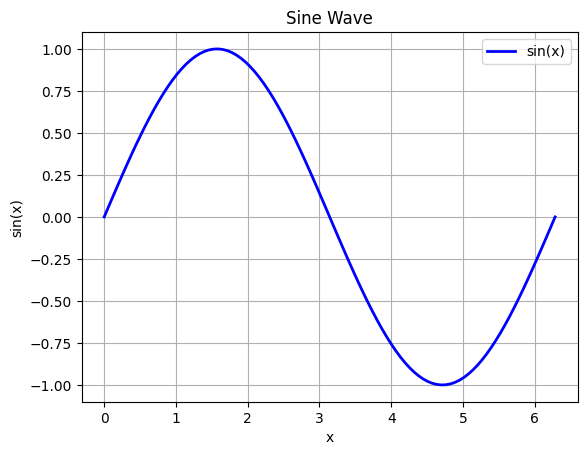

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Create x values
x = np.linspace(0, 2 * np.pi, 100)

# Calculate y values
y = np.sin(x)

# Create the plot
plt.plot(x, y, color="blue", linewidth=2, label="sin(x)")

# Add labels and title
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.title("Sine Wave")

# Add grid and legend
plt.grid(True)
plt.legend()

# Display the plot
plt.show()


MATPLOT

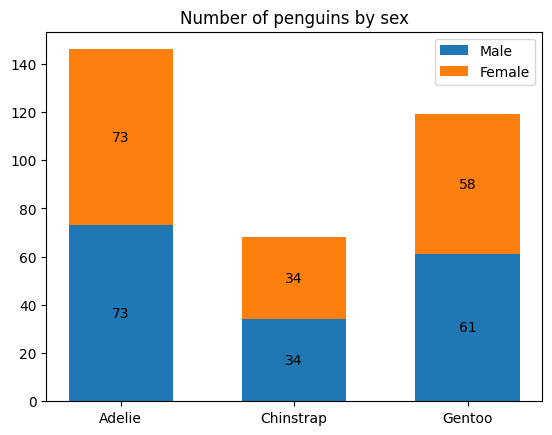

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
species = ('Adelie', 'Chinstrap', 'Gentoo')
sex_counts = {'Male': np.array([73, 34, 61]),'Female': np.array([73, 34, 58]),}
width = 0.6
# the width of the bars: can also be len(x) sequence


fig, ax = plt.subplots()
bottom = np.zeros(3)

for sex, sex_count in sex_counts.items():
    p = ax.bar(species, sex_count, width, label=sex, bottom=bottom)
    bottom += sex_count

    ax.bar_label(p, label_type='center')

ax.set_title('Number of penguins by sex')
ax.legend()

plt.show()

SCIPY

In [ ]:
import scipy.integrate as integrate
import scipy.special as special
result = integrate.quad(lambda x: x**2, 0, 5)
result

(41.66666666666666, 4.625929269271485e-13)

In [ ]:
n = int(input("Enter n:"))
sum_n=n*(n+1)//2
print("Sum of first natural nos:",sum_n)

Enter n:5
Sum of first natural nos: 15
